# 06 · RNN and LSTM

A recurrent network reads a sequence one step at a time, carrying a hidden state $h_t$ that summarizes the past.

**Vanilla RNN**
$$h_t=\tanh(x_tW_{xh}+h_{t-1}W_{hh}+b)$$
Training uses **backpropagation through time (BPTT)**: unroll the loop and run the chain rule backward through every step. The gradient reaching step $t$ passes through $T-t$ multiplications by $W_{hh}^{\top}\operatorname{diag}(1-h^2)$ — if that factor is below 1 the gradient **vanishes**, above 1 it **explodes**.

**LSTM** adds a separate cell state $c_t$ with additive updates and three gates (input $i$, forget $f$, output $o$):
$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\qquad h_t=o_t\odot\tanh(c_t)$$
The cell-state path is a near-linear "highway": when $f\approx1$ the gradient flows back almost unchanged.

## The experiment
A $\pm1$ marker appears **only at $t=0$**; the other $T$ steps are noise. The label is the marker's sign, so the network must carry one bit across the whole sequence.

**Honest finding:** with only 80 sequences this toy task is solved by *both* models, so accuracy cannot tell them apart. What clearly differs is **gradient flow**, measured at initialization — that is what we assert.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## Vanilla RNN cell
`recurrent_gain < 1` makes $W_{hh}$ contractive (spectral radius ≈ gain) — the regime where vanishing gradients bite. `grad_norms` records $\lVert dh_t\rVert$ per step so we can inspect gradient flow.

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


class RNNCell:
    has_params = True

    def __init__(self, input_dim, hidden_size, l2=0.0, recurrent_gain=0.5):
        # recurrent_gain<1 => contractive Whh (spectral radius ~gain), the regime where vanishing gradients bite
        self.Wxh = np.random.randn(input_dim, hidden_size) / np.sqrt(input_dim)
        self.Whh = np.random.randn(hidden_size, hidden_size) * recurrent_gain / np.sqrt(hidden_size)
        self.bh = np.zeros((1, hidden_size))
        self.l2 = l2
        self.grad_norms = []  # |dh| per timestep, chronological — shows vanishing gradient

    def forward(self, X, training=True):
        N, T, D = X.shape
        H = self.Whh.shape[0]
        h = np.zeros((N, H))
        self.cache = []
        for t in range(T):
            x_t = X[:, t, :]
            a = x_t @ self.Wxh + h @ self.Whh + self.bh
            h_new = np.tanh(a)
            self.cache.append((x_t, h, h_new))
            h = h_new
        return h  # final hidden state only — that's all the classifier reads

    def backward(self, grad_output, lr):
        T = len(self.cache)
        dWxh = np.zeros_like(self.Wxh)
        dWhh = np.zeros_like(self.Whh)
        dbh = np.zeros_like(self.bh)
        dh = grad_output
        self.grad_norms = []
        for t in reversed(range(T)):
            x_t, h_prev, h_new = self.cache[t]
            self.grad_norms.append(np.linalg.norm(dh))
            dtanh = dh * (1 - h_new ** 2)
            dWxh += x_t.T @ dtanh
            dWhh += h_prev.T @ dtanh
            dbh += dtanh.sum(axis=0, keepdims=True)
            dh = dtanh @ self.Whh.T
        self.grad_norms.reverse()  # now chronological: t=0 .. T-1

        self.Wxh -= lr * (dWxh + self.l2 * self.Wxh)
        self.Whh -= lr * (dWhh + self.l2 * self.Whh)
        self.bh -= lr * dbh

## LSTM cell
Gates are computed from one combined matrix, `a = x@Wx + h@Wh + b`, split into $[i,f,o,g]$.

Two initialization details that mattered here:
- **Forget-gate bias = 3.** $\sigma(0)=0.5$ would halve the memory every step ($0.5^{40}\approx10^{-12}$); $\sigma(3)\approx0.95$ keeps it open.
- **Input weights ∝ $1/\sqrt{\text{input\_dim}}$**, otherwise the one-dimensional marker is too weak a signal.

In [3]:
class LSTMCell:
    has_params = True

    def __init__(self, input_dim, hidden_size, l2=0.0):
        H = hidden_size
        self.Wx = np.random.randn(input_dim, 4 * H) / np.sqrt(input_dim)
        self.Wh = np.random.randn(H, 4 * H) / np.sqrt(H)
        self.b = np.zeros((1, 4 * H))
        self.b[:, H:2 * H] = 3.0  # forget-gate bias: σ(3)≈0.95 keeps memory open; σ(0)=0.5 erases it in ~40 steps
        self.H = H
        self.l2 = l2
        self.grad_norms = []

    def forward(self, X, training=True):
        N, T, D = X.shape
        H = self.H
        h = np.zeros((N, H))
        c = np.zeros((N, H))
        self.cache = []
        for t in range(T):
            x_t = X[:, t, :]
            a = x_t @ self.Wx + h @ self.Wh + self.b
            ai, af, ao, ag = np.split(a, 4, axis=1)
            i, f, o, g = sigmoid(ai), sigmoid(af), sigmoid(ao), np.tanh(ag)
            c_new = f * c + i * g
            h_new = o * np.tanh(c_new)
            self.cache.append((x_t, h, c, i, f, o, g, c_new))
            h, c = h_new, c_new
        return h

    def backward(self, grad_output, lr):
        T = len(self.cache)
        H = self.H
        dWx = np.zeros_like(self.Wx)
        dWh = np.zeros_like(self.Wh)
        db = np.zeros_like(self.b)
        dh, dc = grad_output, np.zeros((grad_output.shape[0], H))
        self.grad_norms = []
        for t in reversed(range(T)):
            x_t, h_prev, c_prev, i, f, o, g, c = self.cache[t]
            self.grad_norms.append(np.linalg.norm(dh))
            tanh_c = np.tanh(c)

            dc = dc + dh * o * (1 - tanh_c ** 2)
            do = dh * tanh_c
            df = dc * c_prev
            di = dc * g
            dg = dc * i
            dprev_c = dc * f

            dai = di * i * (1 - i)
            daf = df * f * (1 - f)
            dao = do * o * (1 - o)
            dag = dg * (1 - g ** 2)
            da = np.concatenate([dai, daf, dao, dag], axis=1)

            dWx += x_t.T @ da
            dWh += h_prev.T @ da
            db += da.sum(axis=0, keepdims=True)

            dh = da @ self.Wh.T
            dc = dprev_c
        self.grad_norms.reverse()

        self.Wx -= lr * (dWx + self.l2 * self.Wx)
        self.Wh -= lr * (dWh + self.l2 * self.Wh)
        self.b -= lr * db

## Output head, loss, wrapper

In [4]:
class Dense:
    has_params = True

    def __init__(self, input_dim, output_dim):
        self.weights = np.random.randn(input_dim, output_dim) * np.sqrt(2.0 / input_dim)
        self.bias = np.zeros((1, output_dim))

    def forward(self, x, training=True):
        self.input = x
        return np.dot(x, self.weights) + self.bias

    def backward(self, grad_output, lr):
        grad_weights = np.dot(self.input.T, grad_output)
        grad_bias = np.sum(grad_output, axis=0, keepdims=True)
        grad_input = np.dot(grad_output, self.weights.T)
        self.weights -= lr * grad_weights
        self.bias -= lr * grad_bias
        return grad_input

In [5]:
class Sigmoid:
    has_params = False

    def forward(self, x, training=True):
        self.output = sigmoid(x)
        return self.output

    def backward(self, grad_output):
        return grad_output * self.output * (1 - self.output)

In [6]:
class BCELoss:
    def forward(self, y_pred, y_true):
        eps = 1e-15
        yp = np.clip(y_pred, eps, 1 - eps)
        return -np.mean(y_true * np.log(yp) + (1 - y_true) * np.log(1 - yp))

    def backward(self, y_pred, y_true):
        eps = 1e-15
        yp = np.clip(y_pred, eps, 1 - eps)
        return (-(y_true / yp) + (1 - y_true) / (1 - yp)) / y_true.shape[0]

In [7]:
class Model:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, x, training=True):
        for layer in self.layers:
            x = layer.forward(x, training)
        return x

    def backward(self, grad, lr):
        for layer in reversed(self.layers):
            grad = layer.backward(grad, lr) if layer.has_params else layer.backward(grad)

## Data

In [8]:
def make_dataset(n_per_class, T, seed):
    rng = np.random.RandomState(seed)
    N = n_per_class * 2
    X = rng.randn(N, T, 1) * 0.1
    y = np.array([0] * n_per_class + [1] * n_per_class, dtype=float).reshape(-1, 1)
    marker = np.where(y == 1, 1.0, -1.0)
    X[:, 0, 0] = marker[:, 0]
    perm = rng.permutation(N)
    return X[perm], y[perm]

In [9]:
def accuracy(model, X, y):
    preds = (model.forward(X, training=False) >= 0.5).astype(int)
    return np.mean(preds == y)

In [10]:
def train_model(model, X, y, loss_fn, epochs, lr):
    for _ in range(epochs):
        y_pred = model.forward(X, training=True)
        grad = loss_fn.backward(y_pred, y)
        model.backward(grad, lr)

remember the marker at t=0, classify after 40 noisy steps | train 80, test 80 sequences


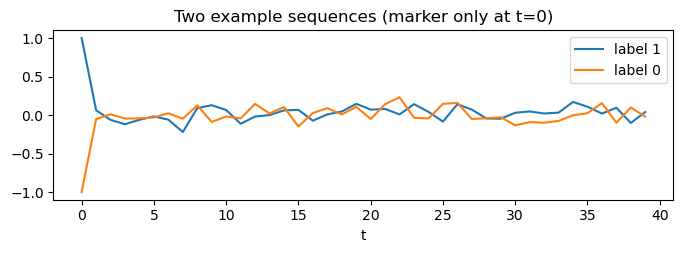

In [11]:
T = 40
X_train, y_train = make_dataset(n_per_class=40, T=T, seed=42)
X_test, y_test = make_dataset(n_per_class=40, T=T, seed=7)
print(f"remember the marker at t=0, classify after {T} noisy steps | train {len(y_train)}, test {len(y_test)} sequences")

plt.figure(figsize=(8, 2.2))
plt.plot(X_train[y_train[:, 0] == 1][0, :, 0], label="label 1"); plt.plot(X_train[y_train[:, 0] == 0][0, :, 0], label="label 0")
plt.title("Two example sequences (marker only at t=0)"); plt.xlabel("t"); plt.legend()
plt.show()

## Train both

In [12]:
loss_fn = BCELoss()
EPOCHS, LR, HIDDEN = 400, 0.1, 16

np.random.seed(1); rnn = Model([RNNCell(1, HIDDEN), Dense(HIDDEN, 1), Sigmoid()])
train_model(rnn, X_train, y_train, loss_fn, EPOCHS, LR)

np.random.seed(1); lstm = Model([LSTMCell(1, HIDDEN), Dense(HIDDEN, 1), Sigmoid()])
train_model(lstm, X_train, y_train, loss_fn, EPOCHS, LR)

print(f"{'Model':<8}{'Train':<10}{'Test'}")
for n, m in [("RNN", rnn), ("LSTM", lstm)]:
    print(f"{n:<8}{accuracy(m, X_train, y_train):<10.2%}{accuracy(m, X_test, y_test):.2%}")
assert accuracy(lstm, X_test, y_test) > 0.85, "LSTM failed to solve the long-delay task"

Model   Train     Test
RNN     100.00%   100.00%
LSTM    100.00%   100.00%


## Gradient flow at initialization
Compare $\lVert dh_0\rVert/\lVert dh_{T-1}\rVert$ — how much of the end-of-sequence gradient survives back to the first step (1.0 = nothing lost). Measured **before training**: after training the loss is ≈0 and all gradients shrink, which would be misleading.

In [13]:
np.random.seed(1)
probes = {"RNN": RNNCell(1, HIDDEN), "LSTM": LSTMCell(1, HIDDEN)}
ratios = {}
for name, cell in probes.items():
    cell.forward(X_train)
    cell.backward(np.ones((len(y_train), HIDDEN)), lr=0.0)   # lr=0: measure only, no update
    ratios[name] = cell.grad_norms[0] / cell.grad_norms[-1]
    print(f"{name:<5} |dh_0| / |dh_{T-1}| = {ratios[name]:.2e}")

assert ratios["RNN"] < 1e-6 < 1e-3 < ratios["LSTM"], "expected RNN gradient to vanish and LSTM's to survive"

RNN   |dh_0| / |dh_39| = 1.26e-15


LSTM  |dh_0| / |dh_39| = 2.35e-01


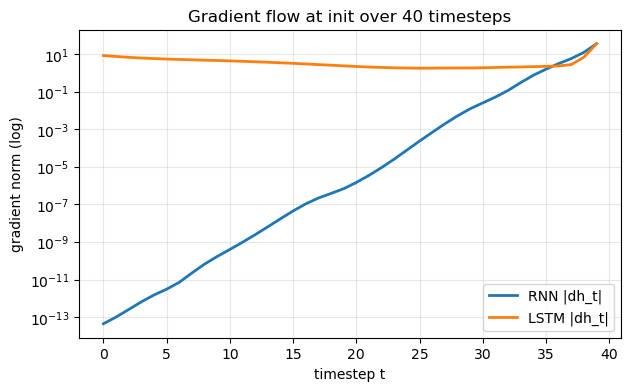

In [14]:
plt.figure(figsize=(7, 4))
for name, cell in probes.items():
    plt.plot(cell.grad_norms, label=f"{name} |dh_t|", linewidth=2)
plt.yscale("log"); plt.xlabel("timestep t"); plt.ylabel("gradient norm (log)")
plt.title(f"Gradient flow at init over {T} timesteps"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

The RNN's gradient decays by ~15 orders of magnitude over 40 steps; the LSTM's barely drops. Longer sequences or harder tasks make this the difference between learning and not learning.

**Next: `07_attention_transformer`** — drop recurrence entirely: let every position look at every other position directly.